# 01 - Data Understanding dan Verifikasi Cleansing (A1)
**Tujuan:** memahami data NSL-KDD sampel 25.000 baris, memverifikasi kebersihannya, dan menyerahkan `data_clean.csv` ke tim.

**Input:** `data/raw/NSL-KDD_sample_25000.xlsx` (sheet `Data`)
**Output:** `data/clean/data_clean.csv`, `data/clean/columns_config.json`, `results/cleaning_log.csv`, `results/tabel_*.csv`, `results/figures/*.png`

Catatan: sampling 25.000 baris, penggabungan train+test, pembuangan duplikat awal, dan pembuangan kolom `difficulty` sudah dilakukan **sebelum** berkas ini dibuat. Itu dicatat di bagian Data Understanding laporan, bukan dikerjakan ulang di sini.

In [15]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200, "display.max_columns", 60)

ROOT = Path("..") if Path("../data").exists() else Path(".")
CANDIDATES = [ROOT / "data/raw/NSL-KDD_sample_25000.xlsx", Path("NSL-KDD_sample_25000.xlsx")]
DATA_PATH = next(p for p in CANDIDATES if p.exists())
(ROOT / "data/clean").mkdir(parents=True, exist_ok=True)
(ROOT / "results/figures").mkdir(parents=True, exist_ok=True)
print("Membaca:", DATA_PATH)

Membaca: ..\data\raw\NSL-KDD_sample_25000.xlsx


In [16]:
df = pd.read_excel(DATA_PATH, sheet_name="Data")
assert df.shape == (25000, 45), f"Dimensi tidak sesuai: {df.shape}"
print("Dimensi:", df.shape)
df.head()

Dimensi: (25000, 45)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,jenis_serangan,kategori,target_biner,sumber
0,0,udp,private,SF,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,10,9,0.0,0.0,0.0,0.0,0.9,0.2,0.0,255,9,0.04,0.91,0.10,0.0,0.04,0.0,0.84,0.0,saint,Probe,Serangan,KDDTest+
1,0,udp,domain_u,SF,44,76,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,174,174,0.0,0.0,0.0,0.0,1.0,0.0,0.0,255,250,0.98,0.01,0.01,0.0,0.00,0.0,0.00,0.0,normal,Normal,Normal,KDDTrain+
2,0,icmp,ecr_i,SF,1032,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,253,253,0.0,0.0,0.0,0.0,1.0,0.0,0.0,255,253,0.99,0.01,0.99,0.0,0.00,0.0,0.00,0.0,smurf,DoS,Serangan,KDDTrain+
3,0,udp,private,SF,28,0,0,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,98,98,0.0,0.0,0.0,0.0,1.0,0.0,0.0,255,98,0.38,0.04,0.38,0.0,0.02,0.0,0.00,0.0,teardrop,DoS,Serangan,KDDTrain+
4,0,icmp,ecr_i,SF,1032,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,511,511,0.0,0.0,0.0,0.0,1.0,0.0,0.0,255,192,0.75,0.02,0.75,0.0,0.00,0.0,0.02,0.0,smurf,DoS,Serangan,KDDTrain+


## 1. Definisi kelompok kolom
41 kolom pertama = fitur. Kolom `jenis_serangan`, `kategori`, `target_biner` = label. Kolom `sumber` = metadata. **Label dan metadata tidak boleh menjadi fitur.**

In [17]:
FEATURES = list(df.columns[:41])
CAT = ["protocol_type", "service", "flag"]
NUM = [c for c in FEATURES if c not in CAT]
RAW_LABEL, TARGET5, TARGET2, META = "jenis_serangan", "kategori", "target_biner", "sumber"
assert set([RAW_LABEL, TARGET5, TARGET2, META]).isdisjoint(FEATURES)
print(len(FEATURES), "fitur |", len(CAT), "kategorikal |", len(NUM), "numerik")

41 fitur | 3 kategorikal | 38 numerik


## 2. Inspeksi awal

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 45 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   duration                     25000 non-null  int64  
 1   protocol_type                25000 non-null  str    
 2   service                      25000 non-null  str    
 3   flag                         25000 non-null  str    
 4   src_bytes                    25000 non-null  int64  
 5   dst_bytes                    25000 non-null  int64  
 6   land                         25000 non-null  int64  
 7   wrong_fragment               25000 non-null  int64  
 8   urgent                       25000 non-null  int64  
 9   hot                          25000 non-null  int64  
 10  num_failed_logins            25000 non-null  int64  
 11  logged_in                    25000 non-null  int64  
 12  num_compromised              25000 non-null  int64  
 13  root_shell                 

In [19]:
desc = df[NUM].describe().T
desc.to_csv(ROOT / "results/tabel_statistik_deskriptif.csv")
desc.round(2)

,count,mean,std,min,25%,50%,75%,max
duration,25000.0,513.55,3345.57,0.0,0.00,0.00,0.00,5.771500e+04
src_bytes,25000.0,79914.55,8744135.21,0.0,0.00,45.00,309.00,1.379964e+09
dst_bytes,25000.0,21187.29,2535010.81,0.0,0.00,0.00,392.00,4.002911e+08
land,25000.0,0.00,0.03,0.0,0.00,0.00,0.00,1.000000e+00
wrong_fragment,25000.0,0.07,0.44,0.0,0.00,0.00,0.00,3.000000e+00
urgent,25000.0,0.00,0.04,0.0,0.00,0.00,0.00,3.000000e+00
hot,25000.0,0.49,3.20,0.0,0.00,0.00,0.00,3.000000e+01
num_failed_logins,25000.0,0.02,0.15,0.0,0.00,0.00,0.00,5.000000e+00
logged_in,25000.0,0.41,0.49,0.0,0.00,0.00,1.00,1.000000e+00
num_compromised,25000.0,0.20,8.69,0.0,0.00,0.00,0.00,7.610000e+02


## 3. Data understanding: distribusi

In [20]:
def dist(col):
    t = df[col].value_counts().rename("jumlah").to_frame()
    t["persen"] = (t["jumlah"] / len(df) * 100).round(2)
    return t

for col in [TARGET5, TARGET2, "protocol_type", META]:
    print(f"\n== {col}"); print(dist(col))
t_jenis = dist(RAW_LABEL); t_jenis.to_csv(ROOT / "results/tabel_jenis_serangan.csv")
dist(TARGET5).to_csv(ROOT / "results/tabel_distribusi_kategori.csv")
print("\nJumlah jenis serangan (termasuk normal):", df[RAW_LABEL].nunique())
print("Jumlah nilai service:", df["service"].nunique(), "| flag:", df["flag"].nunique())


== kategori
          jumlah  persen
kategori                
Normal      9001   36.00
DoS         7500   30.00
Probe       4500   18.00
R2L         3880   15.52
U2R          119    0.48

== target_biner
              jumlah  persen
target_biner                
Serangan       15999    64.0
Normal          9001    36.0

== protocol_type
               jumlah  persen
protocol_type                
tcp             19050   76.20
udp              3191   12.76
icmp             2759   11.04

== sumber
           jumlah  persen
sumber                   
KDDTrain+   17884   71.54
KDDTest+     7116   28.46

Jumlah jenis serangan (termasuk normal): 40
Jumlah nilai service: 68 | flag: 11


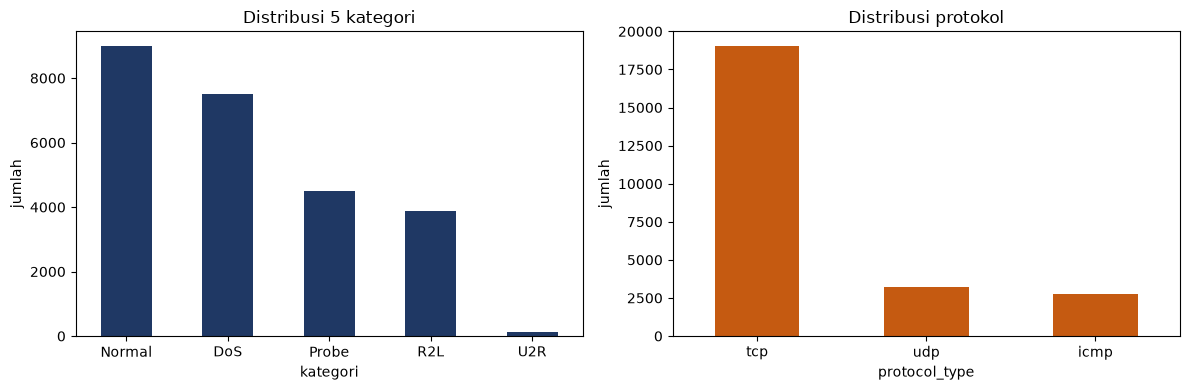

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
dist(TARGET5)["jumlah"].plot.bar(ax=ax[0], color="#1F3864"); ax[0].set_title("Distribusi 5 kategori")
dist("protocol_type")["jumlah"].plot.bar(ax=ax[1], color="#C55A11"); ax[1].set_title("Distribusi protokol")
for a in ax: a.set_ylabel("jumlah"); a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(ROOT / "results/figures/distribusi_kategori_protokol.png", dpi=150); plt.show()

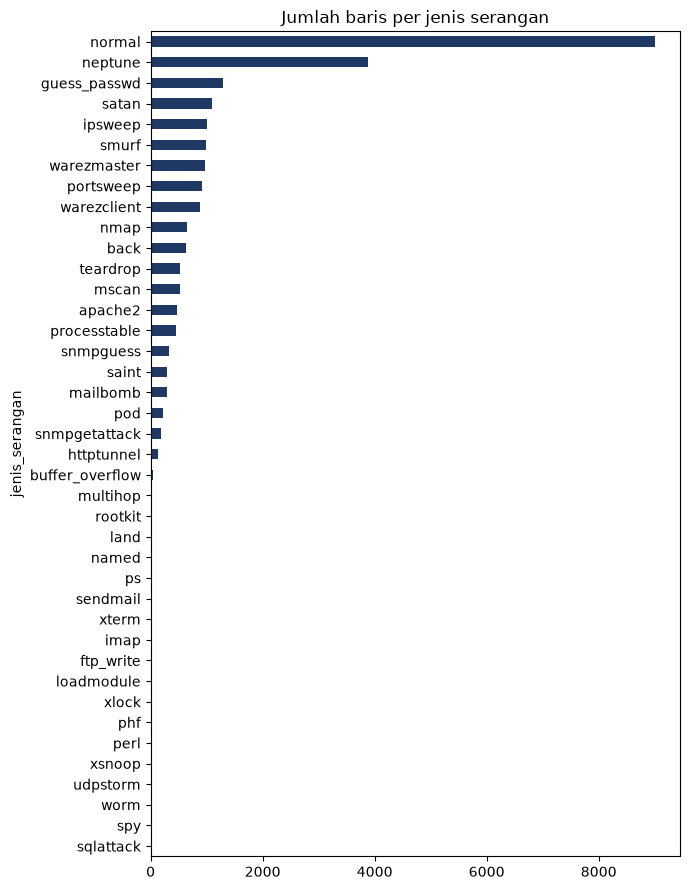

In [22]:
t_jenis["jumlah"].sort_values().plot.barh(figsize=(7, 9), color="#1F3864")
plt.title("Jumlah baris per jenis serangan"); plt.tight_layout()
plt.savefig(ROOT / "results/figures/distribusi_jenis_serangan.png", dpi=150); plt.show()

## 4. Verifikasi cleansing
Setiap pemeriksaan dicatat ke `cleaning_log`. Kolom `status`: OK = lolos, TEMUAN = perlu keputusan.

In [23]:
log = []
def catat(pemeriksaan, hasil, status, tindakan="-"):
    log.append({"pemeriksaan": pemeriksaan, "hasil": hasil, "status": status, "tindakan": tindakan})

# 4.1 missing value
n_miss = int(df.isna().sum().sum())
catat("Missing value (seluruh kolom)", f"{n_miss} sel kosong", "OK" if n_miss == 0 else "TEMUAN")

# 4.2 duplikat baris utuh
n_dup = int(df.duplicated().sum())
catat("Baris duplikat utuh", f"{n_dup} baris", "OK" if n_dup == 0 else "TEMUAN")

# 4.3 tipe data
n_num_ok = all(pd.api.types.is_numeric_dtype(df[c]) for c in NUM)
n_cat_ok = all(not pd.api.types.is_numeric_dtype(df[c]) for c in CAT)
catat("Tipe data (numerik/kategorikal)", f"numerik={n_num_ok}, kategorikal={n_cat_ok}", "OK" if (n_num_ok and n_cat_ok) else "TEMUAN")

# 4.4 rentang kolom rasio (0..1)
RATE = [c for c in NUM if c.endswith("_rate")]
bad_rate = {c: int(((df[c] < 0) | (df[c] > 1)).sum()) for c in RATE}
bad_rate = {k: v for k, v in bad_rate.items() if v}
catat("Kolom *_rate dalam rentang 0..1", f"{len(RATE)} kolom diperiksa, pelanggaran: {bad_rate or 0}", "OK" if not bad_rate else "TEMUAN")

# 4.5 nilai negatif
neg = [c for c in NUM if (df[c] < 0).any()]
catat("Nilai negatif pada kolom numerik", f"kolom: {neg or 'tidak ada'}", "OK" if not neg else "TEMUAN")

# 4.6 kolom biner harus 0/1
BIN = ["land", "logged_in", "root_shell", "su_attempted", "is_host_login", "is_guest_login"]
bad_bin = {c: sorted(df[c].unique().tolist()) for c in BIN if not set(df[c].unique()) <= {0, 1}}
catat("Kolom biner hanya bernilai 0/1", f"melanggar: {bad_bin or 'tidak ada'}", "OK" if not bad_bin else "TEMUAN")

# 4.7 kategorikal: spasi dan nilai
spasi = [c for c in CAT if (df[c].astype(str).str.strip() != df[c].astype(str)).any()]
catat("Spasi berlebih pada kolom kategorikal", f"{spasi or 'tidak ada'}", "OK" if not spasi else "TEMUAN")
catat("Nilai protocol_type", str(sorted(df["protocol_type"].unique())), "OK" if set(df["protocol_type"]) == {"tcp", "udp", "icmp"} else "TEMUAN")

# 4.8 konsistensi label: kategori vs jenis_serangan
DOS = {"back", "land", "neptune", "pod", "smurf", "teardrop", "apache2", "udpstorm", "processtable", "worm", "mailbomb"}
PROBE = {"satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"}
U2R = {"buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"}
def peta(a):
    if a == "normal": return "Normal"
    if a in DOS: return "DoS"
    if a in PROBE: return "Probe"
    if a in U2R: return "U2R"
    return "R2L"
salah = int((df[RAW_LABEL].map(peta) != df[TARGET5]).sum())
catat("Konsistensi jenis_serangan -> kategori", f"{salah} baris tidak cocok", "OK" if salah == 0 else "TEMUAN")
salah2 = int((np.where(df[TARGET5] == "Normal", "Normal", "Serangan") != df[TARGET2]).sum())
catat("Konsistensi kategori -> target_biner", f"{salah2} baris tidak cocok", "OK" if salah2 == 0 else "TEMUAN")

# 4.9 fitur identik tapi label berbeda (konflik label)
g = df.groupby(FEATURES, dropna=False)
konflik = df[g[RAW_LABEL].transform("nunique") > 1]
n_pasang = konflik.groupby(FEATURES, dropna=False).ngroups
lintas = konflik.groupby(FEATURES, dropna=False)[TARGET5].nunique().gt(1).sum()
catat("Baris dengan fitur identik tetapi label berbeda",
      f"{n_pasang} kelompok ({len(konflik)} baris); {int(lintas)} lintas kategori, {n_pasang - int(lintas)} dalam kategori sama",
      "OK" if n_pasang == 0 else "TEMUAN", "Dibiarkan, dicatat sebagai keterbatasan" if n_pasang else "-")

# 4.10 sebaran sumber dan kolom label tidak masuk fitur
catat("Label/metadata tidak ada di daftar fitur", f"fitur={len(FEATURES)} kolom", "OK")
pd.DataFrame(log)

,pemeriksaan,hasil,status,tindakan
0,Missing value (seluruh kolom),0 sel kosong,OK,-
1,Baris duplikat utuh,0 baris,OK,-
2,Tipe data (numerik/kategorikal),"numerik=True, kategorikal=True",OK,-
3,Kolom *_rate dalam rentang 0..1,"15 kolom diperiksa, pelanggaran: 0",OK,-
4,Nilai negatif pada kolom numerik,kolom: tidak ada,OK,-
5,Kolom biner hanya bernilai 0/1,"melanggar: {'su_attempted': [0, 1, 2]}",TEMUAN,-
6,Spasi berlebih pada kolom kategorikal,tidak ada,OK,-
7,Nilai protocol_type,"['icmp', 'tcp', 'udp']",OK,-
8,Konsistensi jenis_serangan -> kategori,0 baris tidak cocok,OK,-
9,Konsistensi kategori -> target_biner,0 baris tidak cocok,OK,-


## 5. Keputusan cleansing
**a. `su_attempted` bernilai 2.** Kolom ini seharusnya biner (0/1). Nilai 2 adalah keanehan yang dikenal pada NSL-KDD. Keputusan: ubah 2 menjadi 1 dan catat di log.

In [24]:
n2 = int((df["su_attempted"] == 2).sum())
print("Baris su_attempted == 2:", n2, "| kategori:", df.loc[df.su_attempted == 2, TARGET5].value_counts().to_dict())
df["su_attempted"] = df["su_attempted"].replace(2, 1)
assert set(df["su_attempted"].unique()) <= {0, 1}
catat("Perbaikan su_attempted", f"{n2} baris bernilai 2 diubah menjadi 1", "SELESAI", "Recode 2 -> 1")

Baris su_attempted == 2: 9 | kategori: {'Normal': 9}


**b. Konflik label.** Kelompok baris berfitur identik tetapi label berbeda dibiarkan karena jumlahnya sangat kecil dan mencerminkan ambiguitas nyata di data. Cukup dicatat sebagai keterbatasan.

In [25]:
g = df.groupby(FEATURES, dropna=False)
lintas = g[TARGET5].transform("nunique") > 1
print("Baris konflik lintas kategori yang dibuang:", int(lintas.sum()))
df = df[~lintas].reset_index(drop=True)
catat("Buang konflik label lintas kategori", f"{int(lintas.sum())} baris dibuang", "SELESAI", "Drop")

Baris konflik lintas kategori yang dibuang: 10


## 6. Temuan untuk A2 (bahan EDA)

In [26]:
konstan = [c for c in NUM if df[c].nunique() == 1]
nol = (df[NUM] == 0).mean().sort_values(ascending=False)
info_nol = nol.head(15).rename("proporsi_nol").to_frame().round(4)
info_nol.to_csv(ROOT / "results/tabel_proporsi_nol_top15.csv")
print("Kolom konstan:", konstan)
info_nol

Kolom konstan: ['num_outbound_cmds']


,proporsi_nol
num_outbound_cmds,1.0000
is_host_login,0.9996
su_attempted,0.9995
urgent,0.9995
land,0.9991
num_shells,0.9987
num_access_files,0.9969
root_shell,0.9964
num_file_creations,0.9962
num_root,0.9949


## 7. Simpan hasil dan serahkan ke tim

In [28]:
pd.DataFrame(log).to_csv(ROOT / "results/cleaning_log.csv", index=False)
df.to_csv(ROOT / "data/clean/data_clean.csv", index=False)
config = {
    "features": FEATURES, "categorical": CAT, "numerical": NUM,
    "target_5kelas": TARGET5, "target_biner": TARGET2,
    "label_asli_bukan_fitur": RAW_LABEL, "metadata_bukan_fitur": META,
    "urutan_kelas": ["Normal", "DoS", "Probe", "R2L", "U2R"], "random_state": 42,
}
(ROOT / "data/clean/columns_config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")

cek = pd.read_csv(ROOT / "data/clean/data_clean.csv")
assert cek.shape == (24990, 45)
assert cek[TARGET5].value_counts().to_dict() == {"Normal": 8996, "DoS": 7498, "Probe": 4500, "R2L": 3877, "U2R": 119}
print("Tersimpan. Dimensi:", cek.shape)
pd.DataFrame(log)

Tersimpan. Dimensi: (24990, 45)


,pemeriksaan,hasil,status,tindakan
0,Missing value (seluruh kolom),0 sel kosong,OK,-
1,Baris duplikat utuh,0 baris,OK,-
2,Tipe data (numerik/kategorikal),"numerik=True, kategorikal=True",OK,-
3,Kolom *_rate dalam rentang 0..1,"15 kolom diperiksa, pelanggaran: 0",OK,-
4,Nilai negatif pada kolom numerik,kolom: tidak ada,OK,-
5,Kolom biner hanya bernilai 0/1,"melanggar: {'su_attempted': [0, 1, 2]}",TEMUAN,-
6,Spasi berlebih pada kolom kategorikal,tidak ada,OK,-
7,Nilai protocol_type,"['icmp', 'tcp', 'udp']",OK,-
8,Konsistensi jenis_serangan -> kategori,0 baris tidak cocok,OK,-
9,Konsistensi kategori -> target_biner,0 baris tidak cocok,OK,-
